# 02 — Baseline: TF-IDF + Logistic Regression

เทรนโมเดลเดิมใหม่ตามข้อสรุปจาก `01_eda` แล้ววัดผลแบบที่เชื่อถือได้ เพื่อเป็น **แถวแรกของตารางเทียบผล**
ที่ WangchanBERTa (Phase 2) ต้องเอาชนะให้ได้

สิ่งที่ notebook นี้ตอบ:
1. baseline ทำได้แค่ไหนบน Wongnai test เมื่อวัดอย่างถูกต้อง
2. เลือก hyperparameter อย่างไรโดยไม่โกง test
3. ข้ามโดเมนไป Wisesight แล้วพังแค่ไหน และพังเพราะอะไร
4. เร็วและเล็กแค่ไหน (อีกครึ่งหนึ่งของการเทียบกับ transformer)

**กติกาที่ใช้ตลอด:** เลือกทุกอย่างบน **val** ส่วน **test แตะตอนท้ายครั้งเดียว**
ถ้าลองหลายแบบแล้วเลือกตัวที่ test ดีสุด ตัวเลข test จะกลายเป็นตัวเลขที่ "ถูกเลือกมา" และสูงกว่าที่โมเดลทำได้จริง

In [1]:
import sys, time, json, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data.splits import wongnai_splits, wisesight_test
from src.cleaner import ThaiTextCleaner
from src.models.baseline import build_baseline
from src.metrics import sentiment_metrics, bootstrap_ci
from src.viz import use_thai_font

FIGS = ROOT / "reports" / "figures"
use_thai_font()

'Thonburi'

## 1. ข้อมูล

`src/data/splits.py` ทำตามการตัดสินใจใน 01: ตัด 3 ดาว, ลบซ้ำ, ลบแถว train ที่ซ้ำกับ test, แบ่ง val 10% แบบ stratified (seed คงที่)
อยู่ใน `src/` ไม่ใช่ใน notebook เพราะ **Phase 2 บน Colab ต้องได้ split เดียวกันเป๊ะ** ไม่งั้นเทียบโมเดลกันไม่ได้

In [2]:
data = wongnai_splits()
data["wisesight"] = wisesight_test()
pd.DataFrame({name: {"rows": len(d), "negative": f"{1 - d.label.mean():.1%}"} for name, d in data.items()})

/Users/riewta/Downloads/mlproj/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,train,val,test,wisesight
rows,25039,2783,4296,1161
negative,8.1%,8.1%,6.0%,58.8%


สังเกต: test (ตามที่ Wongnai publish) มีรีวิวลบ 6.0% น้อยกว่า train/val ที่ 8.1%
แปลว่าตัวเลขบน val กับ test จะต่างกันบ้างแม้โมเดลไม่ได้ overfit ส่วน Wisesight กลับด้าน คือลบเยอะกว่าบวก

ทำความสะอาดด้วย `ThaiTextCleaner` ตัวเดียวกับที่ API ใช้ ถ้า train กับ serve ทำความสะอาดคนละแบบ
โมเดลจะเจอข้อความหน้าตาไม่เหมือนตอนเทรน (เรียกว่า *training-serving skew*) เป็นบั๊กที่หาเจอยากเพราะไม่มี error

In [3]:
cleaner = ThaiTextCleaner()
for d in data.values():
    d["clean"] = [" ".join(cleaner.clean(t)) for t in d.text]

## 2. พื้นขั้นต่ำ: ทายว่า "บวก" ทุกรีวิว

ก่อนดูว่าโมเดลเก่งแค่ไหน ต้องรู้ก่อนว่า "ไม่ฉลาดเลย" ได้คะแนนเท่าไร

In [4]:
results = {}
dummy = DummyClassifier(strategy="most_frequent").fit(data["train"].clean, data["train"].label)
results["always positive"] = sentiment_metrics(data["test"].label, dummy.predict(data["test"].clean))
pd.DataFrame(results).T.round(3)

,macro_f1,f1_negative,f1_positive,accuracy
always positive,0.485,0.0,0.969,0.94


accuracy 94% โดยไม่ได้เรียนรู้อะไรเลย ขณะที่ macro-F1 = 0.485 บอกความจริงว่าโมเดลนี้ใช้ไม่ได้
(F1 ของ class ลบ = 0 เพราะไม่เคยทายลบเลย) นี่คือเหตุผลที่เราดู macro-F1

## 3. เลือก hyperparameter บน val

สองตัวที่มีผลมากที่สุดกับ Logistic Regression บนข้อมูลไม่สมดุล:
- **`C`**: ส่วนกลับของ regularization ค่าน้อยบังคับให้ weight เล็ก (โมเดลเรียบง่าย) ค่ามากปล่อยให้โมเดลเชื่อข้อมูลมากขึ้น
- **`class_weight="balanced"`**: คูณ loss ของ class ลบให้หนักขึ้น (~6 เท่า) เพื่อให้โมเดล "สนใจ" class ที่มีน้อย

In [5]:
grid = []
for class_weight in [None, "balanced"]:
    for C in [0.5, 1, 2, 5, 10, 20, 50, 100]:
        model = build_baseline(C=C, class_weight=class_weight).fit(data["train"].clean, data["train"].label)
        m = sentiment_metrics(data["val"].label, model.predict(data["val"].clean))
        grid.append({"class_weight": class_weight or "none", "C": C, **m})

grid = pd.DataFrame(grid)
grid.pivot(index="C", columns="class_weight", values=["macro_f1", "f1_negative"]).round(3)

macro_f1        f1_negative       
class_weight balanced   none    balanced   none
C                                              
0.5             0.802  0.622       0.643  0.280
1.0             0.813  0.702       0.662  0.436
2.0             0.819  0.768       0.671  0.565
5.0             0.823  0.804       0.678  0.633
10.0            0.823  0.819       0.677  0.661
20.0            0.830  0.831       0.688  0.686
50.0            0.836  0.839       0.698  0.701
100.0           0.834  0.834       0.695  0.692

**อ่านตาราง**
- ที่ `C` ต่ำ `balanced` ช่วยมาก (C=0.5: macro-F1 0.80 vs 0.62) เพราะ regularization แรงทำให้โมเดลถอยไปทาย class ใหญ่
  และการถ่วง weight ช่วยดึงกลับมา แต่พอ `C` สูง ทั้งสองแบบ **วิ่งมาเจอกัน** (~0.83)
  เพราะโมเดลที่ยืดหยุ่นพอแยก class ลบได้เองแล้ว
- รอบแรกผม grid ถึงแค่ C=20 และ C=20 ชนะ **ค่าที่ดีที่สุดอยู่ที่ขอบ grid แปลว่ายังหาไม่จบ** เลยขยายไป 50 และ 100
  ผลคือคะแนนนิ่งแถว 0.83–0.84 แล้วเริ่มลดที่ 100
- ช่วง C=20–100 ต่างกันไม่ถึง 0.01 ซึ่งเล็กกว่า noise ของ val (มีรีวิวลบแค่ ~225 รีวิว) อย่าตีความว่า 50 "ดีกว่า" 20 จริงๆ

In [6]:
best = grid.loc[grid.macro_f1.idxmax()]
print(best[["class_weight", "C", "macro_f1"]].to_dict())
model = build_baseline(C=best.C, class_weight=None if best.class_weight == "none" else best.class_weight)
model.fit(data["train"].clean, data["train"].label);

{'class_weight': 'none', 'C': 50.0, 'macro_f1': 0.839079283887468}


## 4. ปรับ threshold ดีไหม

Logistic Regression ให้ความน่าจะเป็น `P(positive)` แล้วตัดที่ 0.5 โดย default
บนข้อมูลไม่สมดุล การเลื่อน threshold เป็นปุ่มที่ถูกและมักช่วยได้ ลองดูบน val:

best threshold = 0.74  macro-F1 0.840 vs 0.839 at 0.5


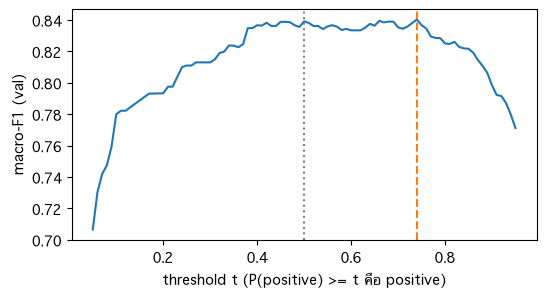

In [7]:
p_val = model.predict_proba(data["val"].clean)[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(data["val"].label, (p_val >= t).astype(int), average="macro") for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]

plt.figure(figsize=(6, 3))
plt.plot(thresholds, f1s)
plt.axvline(0.5, ls=":", c="gray"); plt.axvline(best_t, ls="--", c="C1")
plt.xlabel("threshold t (P(positive) >= t คือ positive)"); plt.ylabel("macro-F1 (val)")
print(f"best threshold = {best_t:.2f}  macro-F1 {max(f1s):.3f} vs {f1s[int(np.argmin(abs(thresholds - 0.5)))]:.3f} at 0.5")

กราฟแบนมากช่วง 0.4–0.8 threshold ที่ "ดีที่สุด" ชนะ 0.5 แค่ **0.001** ซึ่งคือ noise
ลองดูว่าถ้าเชื่อมันแล้วเอาไปใช้กับ test จะเกิดอะไรขึ้น (นี่คือการแตะ test เพื่อสอน ไม่ใช่เพื่อเลือก):

In [8]:
def predict(df, t=0.5):
    return (model.predict_proba(df.clean)[:, 1] >= t).astype(int)

for name in ["test", "wisesight"]:
    for t in [0.5, best_t]:
        results[f"TF-IDF+LR | {name} | t={t:.2f}"] = sentiment_metrics(data[name].label, predict(data[name], t))
results["always positive | wisesight"] = sentiment_metrics(data["wisesight"].label, np.ones(len(data["wisesight"]), int))
pd.DataFrame(results).T.round(3)

,macro_f1,f1_negative,f1_positive,accuracy
always positive,0.485,0.000,0.969,0.940
TF-IDF+LR | test | t=0.50,0.862,0.739,0.985,0.971
TF-IDF+LR | test | t=0.74,0.835,0.691,0.979,0.960
TF-IDF+LR | wisesight | t=0.50,0.473,0.323,0.623,0.516
TF-IDF+LR | wisesight | t=0.74,0.533,0.440,0.627,0.552
always positive | wisesight,0.292,0.000,0.583,0.412


**บทเรียนสำคัญ:** threshold 0.74 ได้ +0.001 บน val แต่ **เสีย 0.027 บน test** (0.862 → 0.835)
นี่คือ overfit กับ val ด้วยพารามิเตอร์ตัวเดียว เพราะเราเลือกจุดสูงสุดของกราฟที่มีแต่ noise

**→ การตัดสินใจ:** ใช้ **t = 0.5** ปรับ threshold เฉพาะเมื่อ val ชนะชัดเจน ไม่ใช่ชนะในระดับทศนิยมตำแหน่งที่สาม

แล้วทำไม Wisesight ดีขึ้นตอน t=0.74? เพราะ Wisesight มีรีวิวลบ 59% ส่วน Wongnai มีแค่ 8%
threshold สูงทำให้ทายลบบ่อยขึ้น ซึ่งบังเอิญตรงกับ Wisesight แต่เราเลือก threshold จาก Wisesight ไม่ได้ เพราะมันคือ test set
ในงานจริงถ้ารู้ว่าข้อมูลปลายทางมี prior ต่าง ต้องมีข้อมูล label จากปลายทางมาปรับ (เรียกว่า *label shift*)

In [9]:
T = 0.5
for name in ["test", "wisesight"]:
    lo, hi = bootstrap_ci(data[name].label, predict(data[name], T))
    print(f"{name:10s} macro-F1 95% CI: [{lo:.3f}, {hi:.3f}]")

test       macro-F1 95% CI: [0.839, 0.884]


wisesight  macro-F1 95% CI: [0.445, 0.502]


**Bootstrap confidence interval:** สุ่ม test set ซ้ำ (แบบใส่คืน) 1,000 รอบแล้วดูว่า macro-F1 แกว่งแค่ไหน
ช่วงกว้างหลายจุดเพราะ test มีรีวิวลบแค่ ~260 รีวิว
ตอนเทียบกับ WangchanBERTa ถ้าช่วงสองโมเดล **ซ้อนกันมาก** ห้ามสรุปว่าตัวหนึ่งชนะ (`bootstrap_ci` อยู่ใน `src/metrics.py` ให้ Phase 2 ใช้ต่อ)

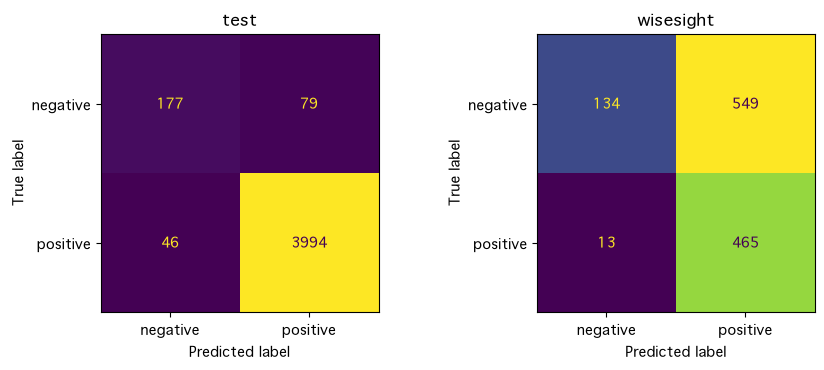

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, name in zip(ax, ["test", "wisesight"]):
    ConfusionMatrixDisplay.from_predictions(
        data[name].label, predict(data[name], T),
        display_labels=["negative", "positive"], colorbar=False, ax=a)
    a.set_title(name)
plt.tight_layout()
plt.savefig(FIGS / "baseline_confusion.png", dpi=120)

- **Wongnai test:** รีวิวลบถูกทายเป็นบวก **79 จาก 256 (31%)** ขณะที่รีวิวบวกผิดแค่ 46 จาก 4,040 (~1%)
  จุดอ่อนคือ **recall ของ class ลบ** ซึ่งเป็น class ที่ธุรกิจสนใจที่สุด
- **Wisesight:** อาการเดียวกันแต่หนักกว่ามาก ข้อความลบถูกทายเป็นบวก **549 จาก 683 (80%)** ส่วนข้อความบวกผิดแค่ 13
  โมเดลเรียนจากโลกที่ 92% เป็นบวก เลยเอียงไปทางบวกเมื่อไม่แน่ใจ

## 5. ความเร็วและขนาด

อีกครึ่งหนึ่งของการเทียบกับ transformer วัดเวลา **ทั้ง clean และ predict** ทีละรีวิว เหมือนที่ API ทำจริง (ไม่ใช่ batch)

In [11]:
def latency_ms(texts):
    out = []
    for t in texts:
        start = time.perf_counter()
        model.predict_proba([" ".join(cleaner.clean(t))])
        out.append((time.perf_counter() - start) * 1000)
    return np.percentile(out, [50, 95])

sample = data["test"].text.sample(300, random_state=0)
p50, p95 = latency_ms(sample)
size_mb = len(pickle.dumps(model)) / 1e6
print(f"latency per review (clean + predict, CPU): p50={p50:.1f} ms  p95={p95:.1f} ms")
print(f"model size: {size_mb:.1f} MB")

latency per review (clean + predict, CPU): p50=0.6 ms  p95=1.5 ms
model size: 1.2 MB


ไม่ถึง 1 ms ต่อรีวิว และไฟล์ราว 1 MB WangchanBERTa (~420 MB, CPU หลายสิบ ms ต่อรีวิว) จะต้องชนะเรื่องคุณภาพ
**มากพอ** ถึงจะคุ้ม และนี่คือคำถามที่ตาราง README ควรตอบ ไม่ใช่แค่ "ตัวไหน F1 สูงกว่า"

## 6. โมเดลเรียนรู้อะไร

ข้อดีของ linear model คืออ่าน weight ได้ตรงๆ: weight ลบมาก = ดันไปทาง negative

In [12]:
vocab = model.named_steps["tfidf"].get_feature_names_out()
coef = pd.Series(model.named_steps["clf"].coef_[0], index=vocab).sort_values()
pd.DataFrame({"-> negative": coef.head(20).index, "-> positive": coef.tail(20).index[::-1]})

,-> negative,-> positive
0,ไม่ อร่อย,อร่อย
1,พอใช้ได้,ไม่ ผิดหวัง
2,แย่มาก,ชอบ
3,แย่,ดีมาก
4,ไม่ ประทับใจ,อร่อย มาก
5,ไม่,เด็ด
6,ไม่ สด,ฟิน
7,ไม่ คุ้ม,ไม่ แพง
8,รสชาติ ธรรมดา,รสชาติ ดี
9,จืด,ชอบ มาก


- **bigram ที่มี "ไม่" ทำงานตามที่หวัง:** "ไม่ อร่อย" ดันไปลบ แต่ "ไม่ ผิดหวัง" และ "ไม่ แพง" ดันไป **บวก**
  ถ้าตัด "ไม่" ทิ้งเป็น stopword หรือใช้แค่ unigram สองคู่หลังจะกลายเป็น "ผิดหวัง" และ "แพง" ซึ่งความหมายตรงข้าม
  นี่คือหลักฐานชัดที่สุดว่า `KEEP_WORDS` + `ngram_range=(1,2)` ถูกต้อง
- คำกลางๆ อย่าง "พอใช้ได้", "ธรรมดา", "ดีกว่า" ดันไปลบ สอดคล้องกับ log-odds ใน 01 (รีวิวลบของ Wongnai สุภาพ)
- **"2 ดาว"** ดันไปลบ: ผู้เขียนพิมพ์คะแนนไว้ในรีวิวเอง โมเดลจึงได้ "คำตอบ" มาบางส่วน
  ใช้ได้กับ Wongnai แต่ไม่ช่วยเลยกับข้อความใน LINE

## 7. ดูตัวอย่างที่ผิด

ตัวเลขบอกว่าผิดแค่ไหน ตัวอย่างบอกว่า **ผิดแบบไหน** ซึ่งบอกว่าต้องแก้ที่โมเดลหรือที่ข้อมูล

In [13]:
def show_errors(name, n=5):
    d = data[name].assign(p=model.predict_proba(data[name].clean)[:, 1])
    for label, title in [(0, "negative predicted positive"), (1, "positive predicted negative")]:
        wrong = d[(d.label == label) & ((d.p >= T) != bool(label))]
        print(f"-- {name}: {title} ({len(wrong)})")
        for _, r in wrong.sample(min(n, len(wrong)), random_state=1).iterrows():
            print(f"  p={r.p:.2f}  {r.text[:150]!r}")

show_errors("test")

-- test: negative predicted positive (79)
  p=0.81  'ร้านกาแฟนี้ ส่วนมากจะมีสาขาตามปั๊มน้ำมัน สาขานี้จะเป็นร้านเล็กๆ แต่ข้างใน คนนั้นเต็ม มีทั้งเด็กและผู้ใหญ่มานั่งคุยงาน\n\nร้านนี้พนักงานบริการดี ยิ้มแย้ม'
  p=0.94  'คาเฟ่แมวหน้าตลาดรถไฟศรีนครินทร์ ไม่มีที่จอดรถจ้าต้องจอดในตลาดเสีย 40 บาท ใครแวะมาช้อปแล้วมากิน ok ร้านแต่งสวยพอเหมาะแบบญี่ปุ่นมินิมอล กลิ่นแมวตลบอบอวล'
  p=0.99  'เป็นร้านที่คนแนะนำค่อนข้างเยอะค่ะ แต่เรากลับไม่ถูกใจเท่าไหร่ เรื่องบริการต้องทำใจนะคะ คนเยอะก็ต้องรอนานเป็นปกติ แต่พนักงานก็พยายามดูแล ยิ้มแย้มแจ่มใสด'
  p=0.67  'โรตีในเมือง อยุ่หน้าร้าน แสงดำรงภูเก็ต หาง่ายที่จอดเยอะ แต่ราคาค่อนข้างแพง ถ้าพูดถึงลักษณะอาหาร\nรวมถึงรสชาติ ไม่ถึงกับอร่อยเท่ากับที่คาดหวัง เพราะไม่ไ'
  p=0.87  'สั่งแบบกลับบ้าน ไก่สับน่องสะโพก320+ ข้าว3ห่อๆละ15 รวมเกือบๆ400 (เนื้อน่องแพงกว่าตั้งเกือบ100) แต่ก็ยอมจ่ายคะเพราะหวังว่าจะเด็ดสมคำร่ำลือ และอยากลองซัก'
-- test: positive predicted negative (46)
  p=0.20  'ร้านนี้อยู่ในเอกมัยซอย 2 ร้านบรรยากาศค่อนข้างเกร๋ ดูดีมีสไตล์ ดูผ่านๆไม่รู้เลยว่าเป็นร้

In [14]:
show_errors("wisesight")

-- wisesight: negative predicted positive (549)
  p=1.00  'สันนี้ก็พิสูจน์แล้วว้างดปิ้งย่างไปยาวๆๆๆๆๆเลย อ้วกแตกคาฮอตพอต เวนในเวน -_-'
  p=0.97  'ฝรั่งถามว่า อาร์ยูซิงเกิล? กูตอบ เยส ไอแอมดริ้งกิ้ง เบียร์สิงห์ อีเหี้ย! ที่พีคกว่านั้นคือ มันไปซื้อเบียร์สิงห์มาให้แดก55555555555555'
  p=0.85  'ไรวะ ทวิตไม่จบเลย จะทวิตว่า กินฟูลมูนขวดเดียว มึนหัวชิบ!! รู้สึกจะอ้วก โหวงเหวง อีบ้า คออ่อนในจุดที่ ขวดเดียวก็จะลงไปกองที่พื้น'
  p=0.78  'ถ้าคิดแบบนี้ แอคคอร์ด แคมรี่ ก็ต้องขายไม่ได้ซิ'
  p=0.80  'นี้แฟนรอcivicตัวใหม่ปีนี้ออก ก็ว่าจะขายmazda3ทิ้งเหมือนกัน แค่ทำสียังลำบากเลย'
-- wisesight: positive predicted negative (13)
  p=0.30  'สนใจนะแต่ไม่มีเวลา😈😈😈😈😈'
  p=0.09  'คนที่ดูบุหรี่ไฟฟ้า ส่วนใหญ่เค้าพยามเลิกบุหรี่มวล พยามเลิกสิ่งเสพติด'
  p=0.15  'ความคิดเห็นส่วนตัว ผมว่าไม่ถึงกับ mazda 2 หรอก แต่จะประหยัดขึ้น อาจจะใกล้เคียง mazda 2 นางฉีดตรง อย่างไงๆ ก็ประหยัดกว่า'
  p=0.07  'ไม่ได้โดนบาบีก้อนนานละ #พูดลอยๆ'
  p=0.41  'สนใจ Mazda 2 ครับ'


(ตัวอย่างแสดงแค่ 150 ตัวอักษรแรก ส่วนที่ทำให้เป็นลบมักอยู่ช่วงหลัง)

**Wongnai, ลบแต่ทายเป็นบวก:** เป็น **รีวิวผสม** แทบทั้งหมด เปิดด้วยคำชม ("พนักงานบริการดี ยิ้มแย้ม", "ร้านแต่งสวย")
แล้วค่อยติแบบสุภาพ ("ไม่ถูกใจเท่าไหร่", "ไม่ถึงกับอร่อยเท่าที่คาดหวัง") TF-IDF นับคำทั้งรีวิวรวมกัน คำชมจึงชนะ
ต่างจาก transformer ที่ดูบริบทและลำดับคำได้ จึงเป็นจุดที่ Phase 2 น่าจะช่วยได้จริง

**Wongnai, บวกแต่ทายเป็นลบ:** เป็นรีวิว **เชิงบรรยาย** (ร้านอยู่ไหน ตกแต่งยังไง) แทบไม่มีคำแสดงความรู้สึก
p อยู่ช่วง 0.2–0.4 คือโมเดลไม่แน่ใจ ซึ่งสมเหตุสมผล

**Wisesight, ลบแต่ทายเป็นบวก:** ภาษาพูดและคำหยาบ ("อ้วกแตก", "รู้สึกจะอ้วก", "55555") และเรื่องรถ
ซึ่ง Wongnai ไม่มีให้เรียน label บางตัวก็ถกเถียงได้ (ความเห็นเรื่องยอดขายรถถูก label เป็นลบ)

**Wisesight, บวกแต่ทายเป็นลบ:** แทบทุกตัวมีคำว่า **"ไม่"** ในความหมายอื่น ("ไม่มีเวลา", "ไม่ถึงกับ", "ไม่ได้โดน...นานละ")
"ไม่" มี weight ลบแรงมาก (จาก 01: z ≈ 54) จึงลากทั้งประโยคไปทางลบ เป็นราคาที่จ่ายจากการพึ่งคำเดียวมากเกินไป

In [15]:
d = data["wisesight"].assign(pred=predict(data["wisesight"], T),
                             n_words=data["wisesight"].clean.str.split().map(len))
d["bucket"] = pd.cut(d.n_words, [-1, 3, 10, 30, 1000], labels=["≤3", "4–10", "11–30", ">30"])
d.groupby("bucket", observed=True).apply(
    lambda g: pd.Series({"rows": len(g), "macro_f1": f1_score(g.label, g.pred, average="macro")}),
    include_groups=False).round(3)

,rows,macro_f1
bucket,,
≤3,303.0,0.567
4–10,437.0,0.418
11–30,342.0,0.380
>30,79.0,0.543


**สมมติฐานจาก 01 ผิด:** ใน EDA ผมเดาว่า "ข้อความสั้น" คือปัญหาหลักของ Wisesight
แต่แยกตามความยาวแล้ว **ข้อความสั้นสุด (≤3 คำ) กลับทำได้ดีที่สุด** และไม่มีแนวโน้มชัดเจน
ปัญหาจริงคือ **หัวข้อ สำนวน และ prior** ที่ต่างกัน ไม่ใช่ความยาว นี่คือเหตุผลที่ต้องทดสอบสมมติฐานด้วยข้อมูลเสมอ

ผลต่อ Phase 2: ข้อความ LINE ที่เกี่ยวกับร้านอาหารอาจไม่แย่เท่า Wisesight เพราะหัวข้อตรงกัน
แต่ยังไม่มีข้อมูลยืนยัน ถ้าเก็บข้อความ LINE จริงที่ label แล้วได้ซัก 100–200 ข้อความ จะเป็น test set ที่มีค่าที่สุด

In [16]:
out = ROOT / "reports" / "metrics"
out.mkdir(parents=True, exist_ok=True)
summary = {
    "model": "TF-IDF + Logistic Regression",
    "params": {"C": float(best.C), "class_weight": best.class_weight, "threshold": T},
    "wongnai_test": sentiment_metrics(data["test"].label, predict(data["test"], T)),
    "wisesight_test": sentiment_metrics(data["wisesight"].label, predict(data["wisesight"], T)),
    "latency_ms_p50": round(float(p50), 1),
    "size_mb": round(size_mb, 1),
}
(out / "baseline.json").write_text(json.dumps(summary, indent=2))
summary

{'model': 'TF-IDF + Logistic Regression',
 'params': {'C': 50.0, 'class_weight': 'none', 'threshold': 0.5},
 'wongnai_test': {'macro_f1': 0.8618161475422702,
  'f1_negative': 0.7390396659707724,
  'f1_positive': 0.984592629113768,
  'accuracy': 0.970903165735568},
 'wisesight_test': {'macro_f1': 0.473107981523951,
  'f1_negative': 0.3228915662650602,
  'f1_positive': 0.6233243967828418,
  'accuracy': 0.5159345391903531},
 'latency_ms_p50': 0.6,
 'size_mb': 1.2}

## 8. สรุป

| | macro-F1 | F1 ลบ | accuracy |
|---|---|---|---|
| ทาย "บวก" ทุกรีวิว (Wongnai test) | 0.485 | 0.000 | 0.940 |
| **TF-IDF + LR (Wongnai test)** | **0.862** | **0.739** | 0.971 |
| TF-IDF + LR (Wisesight, ข้ามโดเมน) | 0.473 | 0.323 | 0.516 |

p50 latency < 1 ms ต่อรีวิว, ขนาด ~1 MB (ผลเก็บไว้ที่ `reports/metrics/baseline.json` ให้ README และ Phase 2 อ่าน)

**เทียบกับตัวเลขเดิมใน README (macro-F1 0.83):** วัดบนคนละชุด (สุ่ม 20% จาก train vs test ที่ publish) จึงเทียบตรงๆ ไม่ได้
ตัวเลขใหม่นี้คือตัวที่ควรใช้ต่อ เพราะ test set มาตรฐานและไม่มี leakage

**สิ่งที่ WangchanBERTa ต้องพิสูจน์ใน Phase 2**
1. Wongnai test: ชนะ 0.862 **นอกช่วง bootstrap CI** ไม่ใช่ชนะแค่ทศนิยม
2. Wisesight: นี่คือจุดที่ baseline อ่อนที่สุด และ pretrained model น่าจะได้เปรียบมากที่สุด
3. คุ้มกับ latency ที่ช้ากว่าหลายสิบเท่าและไฟล์ใหญ่กว่าหลายร้อยเท่าไหม